1. buatlah program untuk pemrosesan citra digital seperti gambar-gambar berikut ini:


a. translasi Citra



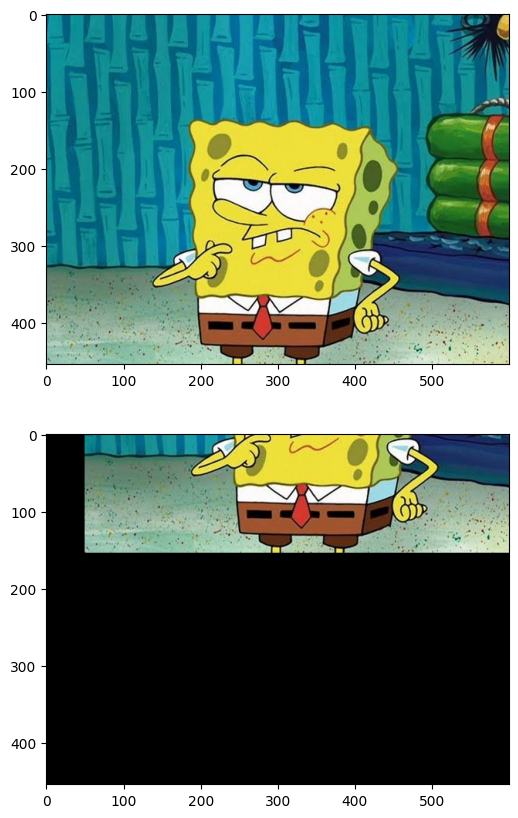

In [11]:
import imageio.v3 as img
import numpy as np
import matplotlib.pyplot as plt

def Translasi(image, shiftX, shiftY):

    imgTranslasi = np.roll(image, shift=shiftY, axis=0)  # Geser vertikal
    imgTranslasi = np.roll(imgTranslasi, shift=shiftX, axis=1)  # Geser horizontal

    # Mengisi bagian yang kosong dengan warna hitam (0)
    if shiftY > 0:
        imgTranslasi[:shiftY, :] = 0  # Bagian atas jika geser ke bawah
    elif shiftY < 0:
        imgTranslasi[shiftY:, :] = 0  # Bagian bawah jika geser ke atas

    if shiftX > 0:
        imgTranslasi[:, :shiftX] = 0  # Bagian kiri jika geser ke kanan
    elif shiftX < 0:
        imgTranslasi[:, shiftX:] = 0  # Bagian kanan jika geser ke kiri

    return imgTranslasi


image = img.imread('/content/images (2).jpg')
imgResult = Translasi(image, shiftX=50, shiftY=-300)

plt.figure(figsize=(10, 10))
plt.subplot(2, 1, 1)
plt.imshow(image)

plt.subplot(2, 1, 2)
plt.imshow(imgResult)

plt.show()

1.B Mirroring

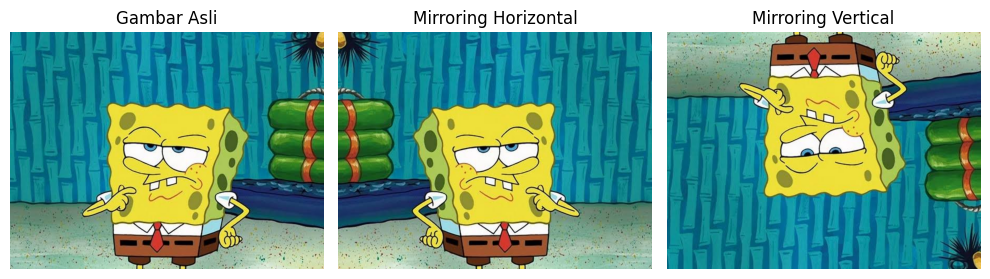

In [16]:
import numpy as np
import imageio.v3 as img
import matplotlib.pyplot as plt

path ='/content/images (2).jpg'
image = img.imread(path)

height, width = image.shape[:2]
horizontal = np.zeros_like(image)
vertical = np.zeros_like(image)

# Mirroring horizontal
for y in range(height):
    for x in range(width):
        horizontal[y, x] = image[y, width - 1 - x]

# Mirroring vertical
for y in range(height):
    for x in range(width):
        vertical[y, x] = image[height - 1 - y, x]

# Menampilkan hasil
plt.figure(figsize=(10, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title('Gambar Asli')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(horizontal)
plt.title('Mirroring Horizontal')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(vertical)
plt.title('Mirroring Vertical')
plt.axis('off')

plt.tight_layout()
plt.show()

1.C  ROTASI CITRA


/tmp/ipykernel_7601/993558763.py:25: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = img.imread('/content/images (2).jpg')


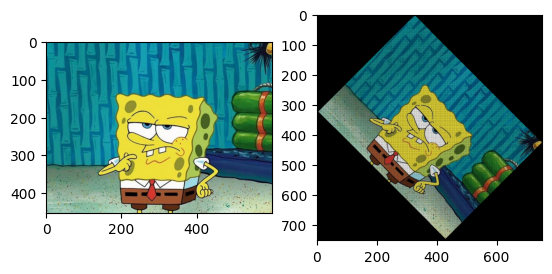

In [17]:
import imageio as img
import numpy as np
import matplotlib.pyplot as plt

def rotateImage(image, degree):
    radian_deg = np.radians(degree)
    cos_deg, sin_deg = np.cos(radian_deg), np.sin(radian_deg)

    height, width = image.shape[:2]
    max_dim = int(np.sqrt(height**2 + width**2))
    outputImage = np.zeros((max_dim, max_dim, 3), dtype=image.dtype)

    centerY, centerX = max_dim//2, max_dim//2

    for y in range(-height//2, height//2):
        for x in range(-width//2, width//2):
            newX = int(cos_deg * x - sin_deg * y) + centerX
            newY = int(sin_deg * x + cos_deg * y) + centerY

            if 0 <= newX < max_dim and 0 <= newY < max_dim:
                outputImage[newY, newX] = image[y + height//2, x + width//2]

    return outputImage

image = img.imread('/content/images (2).jpg')

rotated_image = rotateImage(image, 45)

plt.subplot(1, 2, 1)
plt.imshow(image)

plt.subplot(1, 2, 2)
plt.imshow(rotated_image)

plt.show()

1.D ZOOMING

/tmp/ipykernel_7601/4286196253.py:26: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = img.imread('/content/images (2).jpg')


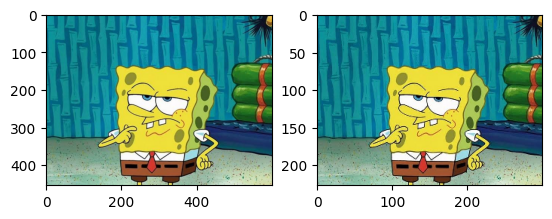

In [19]:
import numpy as np
import imageio as img
import matplotlib.pyplot as plt

def zoomPlus(image, factor):
    height, width = image.shape[:2]
    new_height = int(height / factor)
    new_width = int(width / factor)

    imgZoom = np.zeros((new_height, new_width, 3), dtype=image.dtype)

    for y in range(new_height):
        for x in range(new_width):

            ori_y = int(y * factor)
            ori_x = int(x * factor)

            ori_y = min(ori_y, height - 1)
            ori_x = min(ori_x, width - 1)

            imgZoom[y, x] = image[ori_y, ori_x]

    return imgZoom


image = img.imread('/content/images (2).jpg')
skala = 2.0

imgZoom = zoomPlus(image, skala)
img.imwrite('D:\\z.jpg', imgZoom)

plt.subplot(1, 2, 1)
plt.imshow(image)

plt.subplot(1, 2, 2)
plt.imshow(imgZoom)

plt.show()

2. Ubahlah kode program tersebut yaitu

a. mirroring untuk vertical dan horizontal dilakukan secara bersamaan

b. Rotasi Citra menggunakan pivot di titik (0,0) pojok kiri atas

c. Zoom Minus untuk memperkecil gambar.

2.A Mirroring untuk vertical dan horizontal dilakukan secara bersamaan

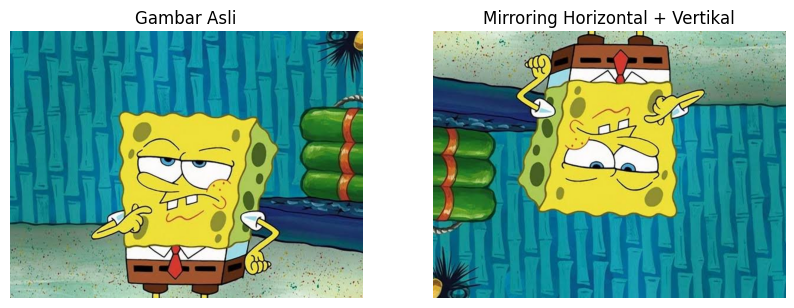

In [20]:
import imageio.v3 as img
import numpy as np
import matplotlib.pyplot as plt

def mirroring_both(image):
    height, width = image.shape[:2]
    mirrored = np.zeros_like(image)

    # Mirroring horizontal dan vertikal secara bersamaan
    for y in range(height):
        for x in range(width):
            new_y = height - 1 - y
            new_x = width - 1 - x
            mirrored[new_y, new_x] = image[y, x]

    return mirrored


# Membaca gambar
image = img.imread('/content/images (2).jpg')

# Melakukan mirroring horizontal dan vertikal
mirrored_image = mirroring_both(image)

# Menampilkan hasil
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title('Gambar Asli')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(mirrored_image)
plt.title('Mirroring Horizontal + Vertikal')
plt.axis('off')

plt.show()

2.B Rotasi Citra menggunakan pivot di titik (0,0) pojok kiri atas


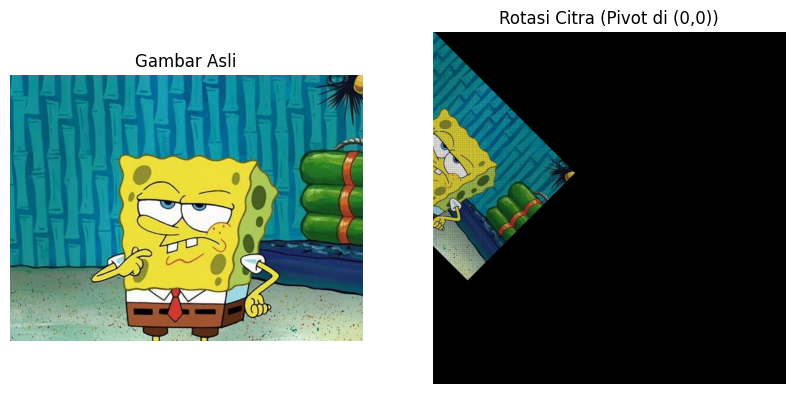

In [21]:
import numpy as np
import imageio.v3 as img
import matplotlib.pyplot as plt

def rotate_citra_pivot_0_0(image, degree):
    radian = np.radians(degree)
    cos_val, sin_val = np.cos(radian), np.sin(radian)

    height, width = image.shape[:2]
    new_height = int(height + width)
    new_width = int(height + width)

    rotated = np.zeros((new_height, new_width, 3), dtype=image.dtype)

    # Matriks rotasi
    for y in range(height):
        for x in range(width):
            new_x = int(cos_val * x - sin_val * y)
            new_y = int(sin_val * x + cos_val * y)

            # Pivot di (0,0), cek agar koordinat tetap dalam batas gambar baru
            if 0 <= new_x < new_width and 0 <= new_y < new_height:
                rotated[new_y, new_x] = image[y, x]

    return rotated


# Membaca gambar
image = img.imread('/content/images (2).jpg')

# Melakukan rotasi 45 derajat dengan pivot di (0,0)
rotated_image = rotate_citra_pivot_0_0(image, 45)

# Menampilkan hasil
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title('Gambar Asli')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(rotated_image)
plt.title('Rotasi Citra (Pivot di (0,0))')
plt.axis('off')

plt.show()

2.C Zoom Minus untuk memperkecil gambar

/tmp/ipykernel_7601/3398650572.py:26: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = img.imread('/content/images (2).jpg')


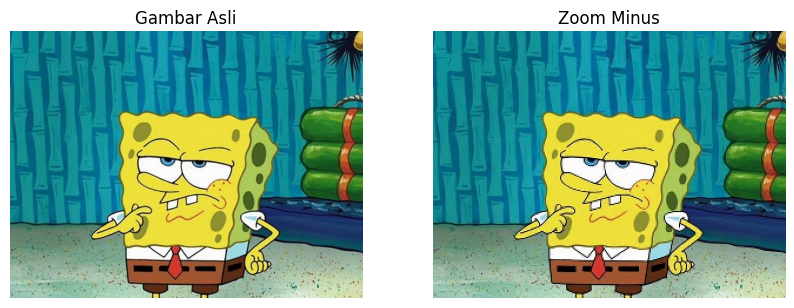

In [22]:
import imageio as img
import numpy as np
import matplotlib.pyplot as plt

def zoomMinus(image, scale):
    height, width = image.shape[:2]

    new_height = int(height * scale)
    new_width = int(width * scale)

    outputImage = np.zeros(
        (new_height, new_width, *image.shape[2:]),
        dtype=image.dtype
    )

    for y in range(new_height):
        for x in range(new_width):
            oldY = int(y / scale)
            oldX = int(x / scale)

            outputImage[y, x] = image[oldY, oldX]

    return outputImage


image = img.imread('/content/images (2).jpg')

# Zoom Minus untuk memperkecil gambar menjadi 50%
zoomed_image = zoomMinus(image, 0.5)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title('Gambar Asli')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(zoomed_image)
plt.title('Zoom Minus')
plt.axis('off')

plt.show()